In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os
from pathlib import Path

folder = Path.cwd()
csv_files = list(folder.glob("*.csv"))

print("Current folder:", folder)
print("\nCSV files found:")
for file in csv_files:
    print(file.name)

Current folder: C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_2_Time_Series_Forecasting

CSV files found:
global_ecommerce_sales (2).csv


In [4]:
import pandas as pd
from pathlib import Path

csv_files = list(Path.cwd().glob("*.csv"))

if csv_files:
    print("CSV files found:")
    for i, file in enumerate(csv_files, start=1):
        print(f"{i}. {file.name}")
else:
    print("No CSV found in this folder. Please check the dataset location.")

CSV files found:
1. global_ecommerce_sales (2).csv


In [5]:
file_path = "global_ecommerce_sales (2).csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (2000, 15)

Column names:
['Order_ID', 'Order_Date', 'Customer_Name', 'Customer_Segment', 'Country', 'Region', 'Product_Category', 'Product_Name', 'Quantity', 'Unit_Price', 'Discount_Percent', 'Total_Sales', 'Shipping_Cost', 'Profit', 'Payment_Method']

First 5 rows:


,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method
0,ORD-11121,2023-01-02,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash on Delivery
1,ORD-11244,2023-01-02,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash on Delivery
2,ORD-10325,2023-01-03,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card
3,ORD-10467,2023-01-03,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,PayPal
4,ORD-11454,2023-01-05,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,1058.14,11.09,253.44,Credit Card


In [6]:
# Convert Order_Date into datetime format
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

# Check the date range
print("First order date:", df["Order_Date"].min())
print("Last order date:", df["Order_Date"].max())

# Check missing dates and sales values
print("\nMissing dates:", df["Order_Date"].isna().sum())
print("Missing sales:", df["Total_Sales"].isna().sum())

# Calculate monthly sales
monthly_sales = (
    df.dropna(subset=["Order_Date", "Total_Sales"])
      .set_index("Order_Date")["Total_Sales"]
      .resample("MS")
      .sum()
)

print("\nMonthly sales:")
display(monthly_sales)

First order date: 2023-01-02 00:00:00
Last order date: 2025-12-31 00:00:00

Missing dates: 0
Missing sales: 0

Monthly sales:


Order_Date
2023-01-01    11275.20
2023-02-01    16943.67
2023-03-01    16056.45
2023-04-01    12185.00
2023-05-01     8218.47
2023-06-01    16191.61
2023-07-01    15667.73
2023-08-01    12971.07
2023-09-01    11989.72
2023-10-01    17794.60
2023-11-01     8475.49
2023-12-01    16674.44
2024-01-01     8015.21
2024-02-01    11979.60
2024-03-01    10550.11
2024-04-01    15615.06
2024-05-01    16594.20
2024-06-01     9435.15
2024-07-01    14937.53
2024-08-01     9883.83
2024-09-01     9636.38
2024-10-01    17426.05
2024-11-01    16413.27
2024-12-01    14664.34
2025-01-01    12321.18
2025-02-01     7337.28
2025-03-01     7772.33
2025-04-01    16403.60
2025-05-01    17621.80
2025-06-01    18068.09
2025-07-01    15065.96
2025-08-01    11302.11
2025-09-01    14375.95
2025-10-01    15874.75
2025-11-01    14781.02
2025-12-01    14041.09
Freq: MS, Name: Total_Sales, dtype: float64

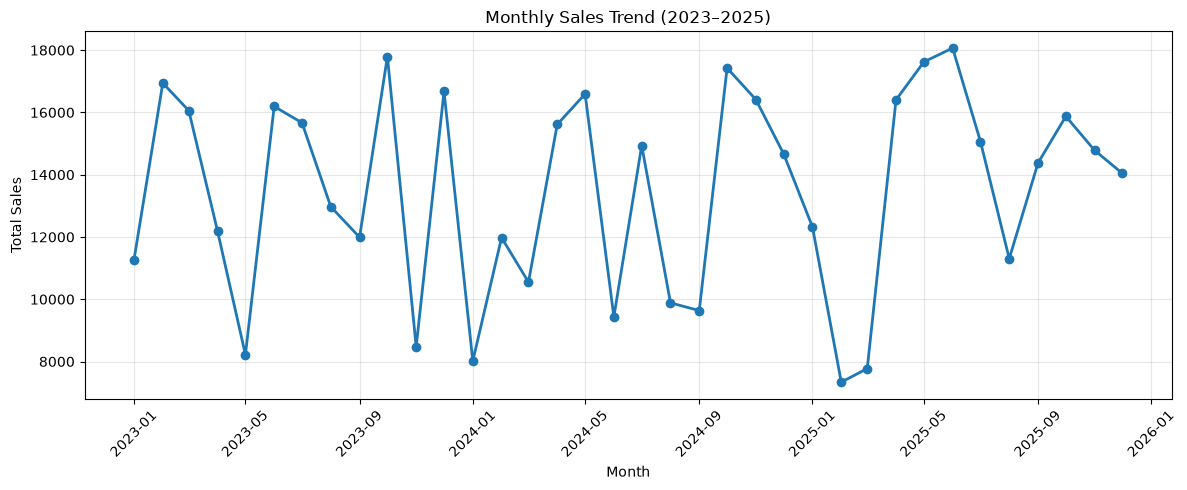

Monthly sales trend chart saved successfully!


In [7]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend (2023–2025)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("monthly_sales_trend.png", dpi=300, bbox_inches="tight")
plt.show()

print("Monthly sales trend chart saved successfully!")

In [8]:
# Split monthly sales into training and testing data
train = monthly_sales[monthly_sales.index < "2025-01-01"]
test = monthly_sales[monthly_sales.index >= "2025-01-01"]

print("Training months:", len(train))
print("Testing months:", len(test))

print("\nTraining period:", train.index.min().strftime("%B %Y"),
      "to", train.index.max().strftime("%B %Y"))

print("Testing period:", test.index.min().strftime("%B %Y"),
      "to", test.index.max().strftime("%B %Y"))

Training months: 24
Testing months: 12

Training period: January 2023 to December 2024
Testing period: January 2025 to December 2025


In [9]:
# Baseline forecast: use the average sales from 2023–2024
baseline_value = train.mean()

baseline_forecast = pd.Series(
    baseline_value,
    index=test.index
)

print("Average monthly sales in training period:", round(baseline_value, 2))

print("\nBaseline forecast for 2025:")
display(baseline_forecast)

Average monthly sales in training period: 13316.42

Baseline forecast for 2025:


Order_Date
2025-01-01    13316.424167
2025-02-01    13316.424167
2025-03-01    13316.424167
2025-04-01    13316.424167
2025-05-01    13316.424167
2025-06-01    13316.424167
2025-07-01    13316.424167
2025-08-01    13316.424167
2025-09-01    13316.424167
2025-10-01    13316.424167
2025-11-01    13316.424167
2025-12-01    13316.424167
Freq: MS, dtype: float64

In [10]:
# Improved forecast using Linear Regression

train_x = np.arange(len(train)).reshape(-1, 1)
test_x = np.arange(len(train), len(train) + len(test)).reshape(-1, 1)

trend_model = LinearRegression()
trend_model.fit(train_x, train.values)

trend_forecast = pd.Series(
    trend_model.predict(test_x),
    index=test.index
)

print("Linear Regression forecast for 2025:")
display(trend_forecast.round(2))

Linear Regression forecast for 2025:


Order_Date
2025-01-01    13388.40
2025-02-01    13394.15
2025-03-01    13399.91
2025-04-01    13405.67
2025-05-01    13411.43
2025-06-01    13417.19
2025-07-01    13422.94
2025-08-01    13428.70
2025-09-01    13434.46
2025-10-01    13440.22
2025-11-01    13445.97
2025-12-01    13451.73
Freq: MS, dtype: float64

In [11]:
# Calculate forecast accuracy
baseline_mae = mean_absolute_error(test, baseline_forecast)
baseline_rmse = np.sqrt(mean_squared_error(test, baseline_forecast))

trend_mae = mean_absolute_error(test, trend_forecast)
trend_rmse = np.sqrt(mean_squared_error(test, trend_forecast))

comparison = pd.DataFrame({
    "Model": ["Baseline (Training Average)", "Linear Regression"],
    "MAE": [baseline_mae, trend_mae],
    "RMSE": [baseline_rmse, trend_rmse]
})

comparison = comparison.round(2)

print("Forecast Model Comparison:")
display(comparison)

Forecast Model Comparison:


,Model,MAE,RMSE
0,Baseline (Training Average),2852.81,3361.29
1,Linear Regression,2806.74,3341.72


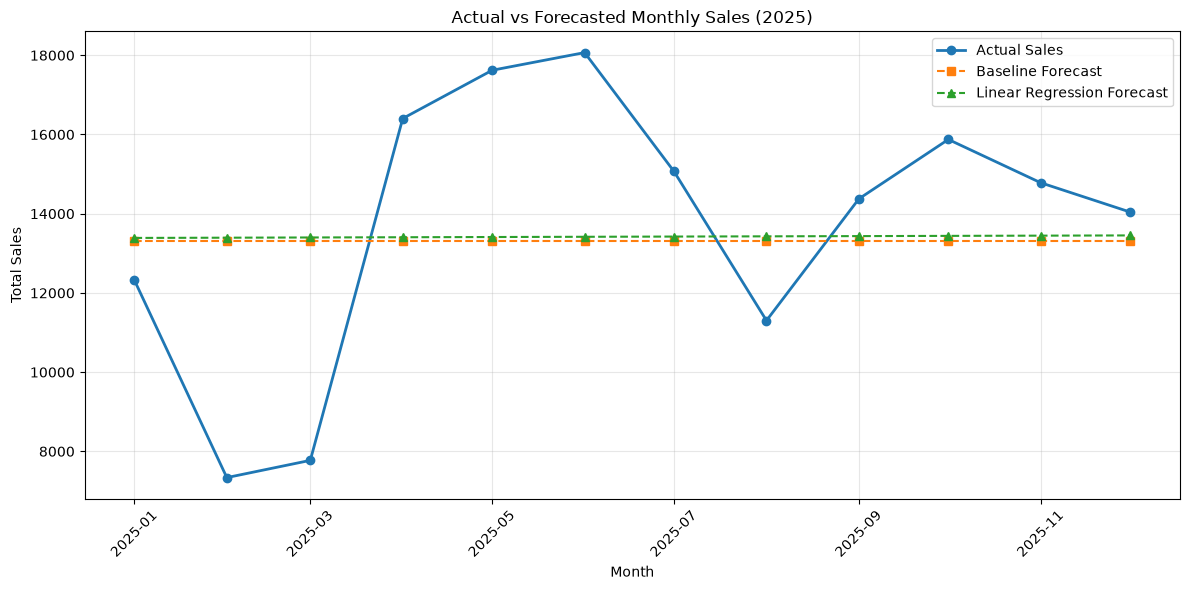

Forecast comparison chart saved successfully!


In [12]:
plt.figure(figsize=(12, 6))

plt.plot(test.index, test.values, marker="o",
         linewidth=2, label="Actual Sales")

plt.plot(test.index, baseline_forecast.values, marker="s",
         linestyle="--", label="Baseline Forecast")

plt.plot(test.index, trend_forecast.values, marker="^",
         linestyle="--", label="Linear Regression Forecast")

plt.title("Actual vs Forecasted Monthly Sales (2025)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("actual_vs_forecasted_sales.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Forecast comparison chart saved successfully!")

In [13]:
# Combine actual sales and both forecasts
forecast_results = pd.DataFrame({
    "Actual_Sales": test,
    "Baseline_Forecast": baseline_forecast,
    "Linear_Regression_Forecast": trend_forecast
})

# Save results in the project folder
forecast_results.to_csv("sales_forecast_results.csv", index_label="Order_Date")

print("Forecast results saved successfully!")
display(forecast_results.round(2))

Forecast results saved successfully!


,Actual_Sales,Baseline_Forecast,Linear_Regression_Forecast
Order_Date,,,
2025-01-01,12321.18,13316.42,13388.40
2025-02-01,7337.28,13316.42,13394.15
2025-03-01,7772.33,13316.42,13399.91
2025-04-01,16403.60,13316.42,13405.67
2025-05-01,17621.80,13316.42,13411.43
2025-06-01,18068.09,13316.42,13417.19
2025-07-01,15065.96,13316.42,13422.94
2025-08-01,11302.11,13316.42,13428.70
2025-09-01,14375.95,13316.42,13434.46


In [14]:
best_model = (
    "Linear Regression"
    if trend_mae < baseline_mae and trend_rmse < baseline_rmse
    else "Baseline (Training Average)"
)

print("PROJECT CONCLUSION")
print("------------------")
print("1. Monthly e-commerce sales data from January 2023 to December 2025 was analyzed.")
print("2. The first 24 months were used for training and the final 12 months for testing.")
print(f"3. Baseline MAE: {baseline_mae:.2f}")
print(f"4. Baseline RMSE: {baseline_rmse:.2f}")
print(f"5. Linear Regression MAE: {trend_mae:.2f}")
print(f"6. Linear Regression RMSE: {trend_rmse:.2f}")
print(f"7. Best model based on both error metrics: {best_model}")
print("8. Linear Regression performed only slightly better, so forecasts should be")
print("   treated as estimates. Additional seasonal models may improve accuracy.")

PROJECT CONCLUSION
------------------
1. Monthly e-commerce sales data from January 2023 to December 2025 was analyzed.
2. The first 24 months were used for training and the final 12 months for testing.
3. Baseline MAE: 2852.81
4. Baseline RMSE: 3361.29
5. Linear Regression MAE: 2806.74
6. Linear Regression RMSE: 3341.72
7. Best model based on both error metrics: Linear Regression
8. Linear Regression performed only slightly better, so forecasts should be
   treated as estimates. Additional seasonal models may improve accuracy.


In [15]:
readme = """# Level 3 - Task 2: Time Series Forecasting

## Project Overview
This project analyzes monthly sales for a global e-commerce dataset
and compares two forecasting methods.

## Dataset
- Source: Global E-Commerce Sales & Customer Analytics
- File: global_ecommerce_sales (2).csv
- Records: 2,000
- Columns: 15
- Date range: January 2023 to December 2025
- Target: Total_Sales

## Methodology
1. Converted Order_Date to datetime format.
2. Aggregated daily transactions into monthly sales.
3. Visualized the monthly sales trend.
4. Used January 2023 to December 2024 for training.
5. Used January 2025 to December 2025 for testing.
6. Compared a training-average baseline with Linear Regression.

## Results

| Model | MAE | RMSE |
|---|---:|---:|
| Baseline (Training Average) | 2852.81 | 3361.29 |
| Linear Regression | 2806.74 | 3341.72 |

## Conclusion
Linear Regression performed slightly better than the baseline
on both MAE and RMSE. However, the improvement was small.
Monthly sales fluctuated, so additional seasonal forecasting
methods may improve future predictions.

## Output Files
- monthly_sales_trend.png
- actual_vs_forecasted_sales.png
- sales_forecast_results.csv
- Level_3_Task_2_Time_Series_Forecasting.ipynb
- README.md
"""

from pathlib import Path

Path("README.md").write_text(readme, encoding="utf-8")
print("README.md created successfully!")
print("Saved at:", Path("README.md").resolve())

README.md created successfully!
Saved at: C:\Users\basav\OneDrive\Documents\SAN_Data_Science_Internship\Level 3\Task_2_Time_Series_Forecasting\README.md


In [16]:
from pathlib import Path

folder = Path.cwd()

required_files = [
    "global_ecommerce_sales (2).csv",
    "monthly_sales_trend.png",
    "actual_vs_forecasted_sales.png",
    "sales_forecast_results.csv",
    "README.md"
]

print("PROJECT FILE CHECK")
print("-" * 30)

for name in required_files:
    status = "FOUND" if (folder / name).exists() else "MISSING"
    print(f"{name}: {status}")

PROJECT FILE CHECK
------------------------------
global_ecommerce_sales (2).csv: FOUND
monthly_sales_trend.png: FOUND
actual_vs_forecasted_sales.png: FOUND
sales_forecast_results.csv: FOUND
README.md: FOUND
